# Week 2 — Day 1 — Exercises XP Ninja

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'analysis_helpers.py').exists():
    if root == root.parent:
        raise FileNotFoundError('Ouvrir depuis Week2/day1 ou un sous-dossier')
    root = root.parent
sys.path.insert(0, str(root))
from analysis_helpers import *
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)


Source : chapitre Octopus 4786. Analyse exploratoire, sans modèle prédictif entraîné ni affirmation causale.

## Exercice 1 — EDA : Medical Cost Personal Dataset
Application des étapes du tutoriel d’Uğur Savcı : question métier, variables, inspection, nettoyage, analyses et visualisations. Source des données : [copie publique de insurance.csv](https://github.com/stedy/Machine-Learning-with-R-datasets/blob/master/insurance.csv), dataset Medical Cost Personal également distribué sur Kaggle. Question : quels profils présentent des charges observées plus élevées ? L'EDA prépare une éventuelle prévision ; elle ne calcule pas une tarification individuelle.

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Doublons : 1
Charges hors bornes IQR : 139


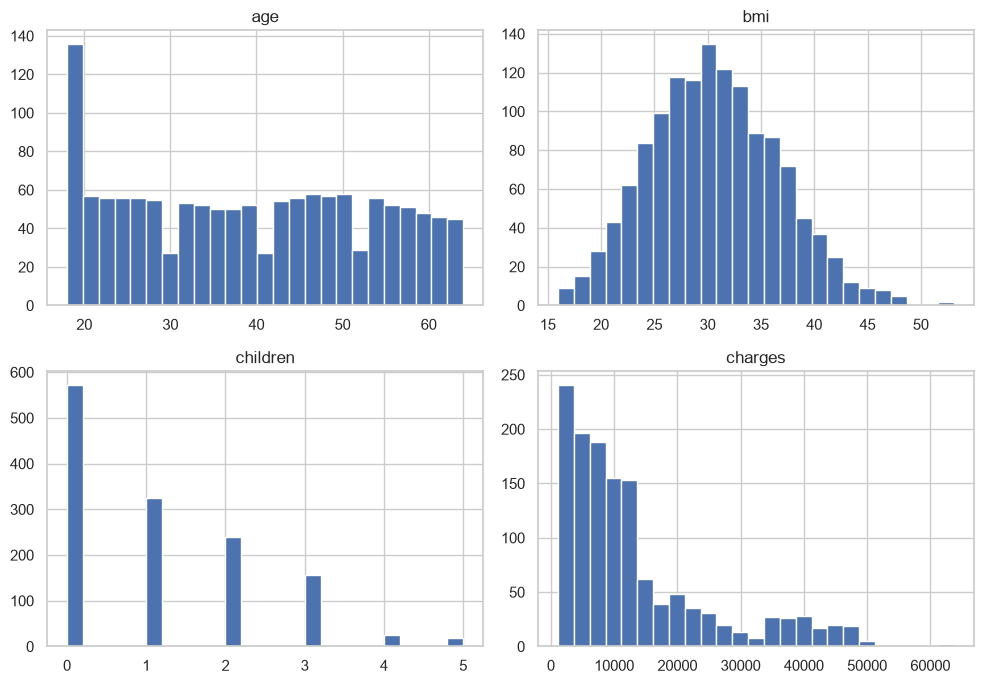

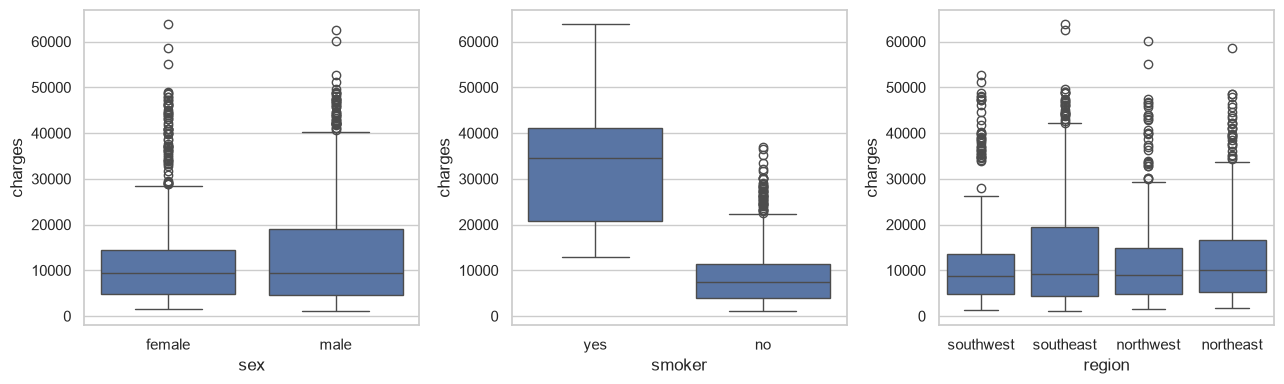

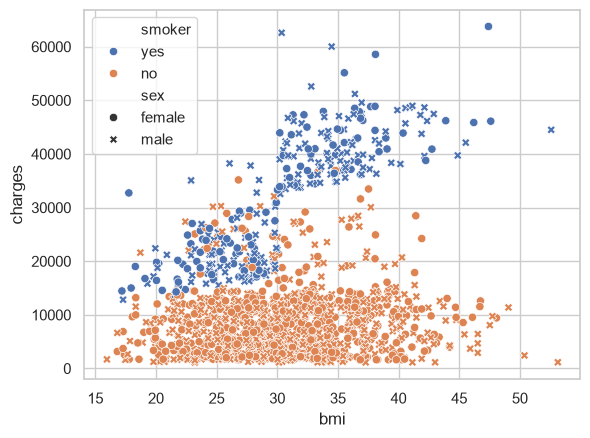

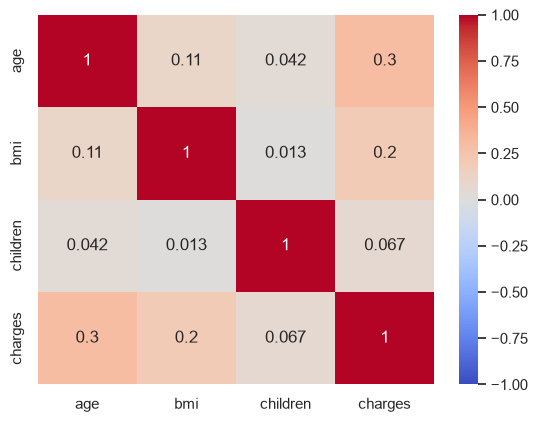

,count,mean,median
smoker,,,
no,1063,8440.660307,7345.72660
yes,274,32050.231832,34456.34845


In [2]:
insurance = pd.read_csv(DATA/'insurance.csv')
display(insurance.head()); insurance.info(); display(insurance.describe(include='all'))
display(insurance.isna().sum());print('Doublons :',insurance.duplicated().sum())
insurance_clean = insurance.drop_duplicates().copy()
assert insurance_clean['charges'].ge(0).all()
q1,q3 = insurance_clean['charges'].quantile([.25,.75]); iqr=q3-q1
print('Charges hors bornes IQR :',((insurance_clean['charges']<q1-1.5*iqr)|(insurance_clean['charges']>q3+1.5*iqr)).sum())
insurance_clean.to_csv(RESULTS/'insurance_clean.csv',index=False)
insurance_clean[['age','bmi','children','charges']].hist(figsize=(10,7),bins=25);plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,col in zip(axs,['sex','smoker','region']):
    sns.boxplot(data=insurance_clean,x=col,y='charges',ax=ax)
plt.tight_layout();plt.show()
sns.scatterplot(data=insurance_clean,x='bmi',y='charges',hue='smoker',style='sex');plt.show()
sns.heatmap(insurance_clean.select_dtypes('number').corr(),annot=True,cmap='coolwarm',vmin=-1,vmax=1);plt.show()
display(insurance_clean.groupby('smoker')['charges'].agg(['count','mean','median']))

Âge et nombre d'enfants sont discrets ; BMI et charges continus ; sexe, tabagisme et région catégoriels. Un doublon exact est écarté dans une copie, avec prudence : sans identifiant, deux individus peuvent partager toutes les valeurs. Les charges élevées sont conservées : dépasser une borne IQR n'est pas une erreur. Le tabagisme distingue fortement les charges observées ; les relations BMI/charges diffèrent selon ce groupe. Une analyse observationnelle ne prouve pas un effet causal et n'établit pas une politique de tarification juste. Les données ne suffisent pas à mesurer la qualité future d'un modèle.

## Exercice 2 — Titanic : inspection, nettoyage et EDA

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


,manquants avant
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


,manquants après
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


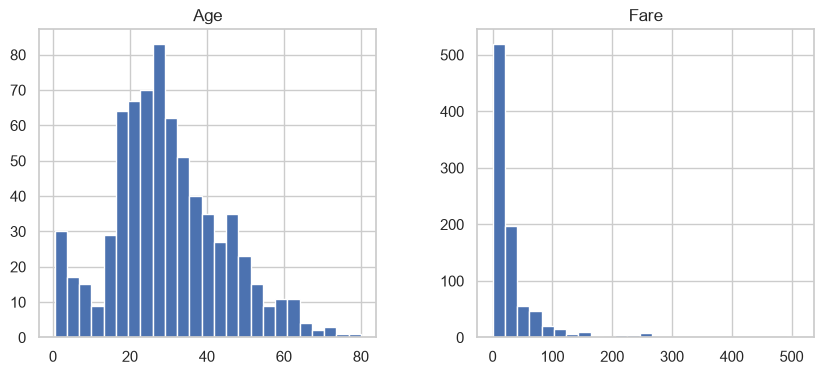

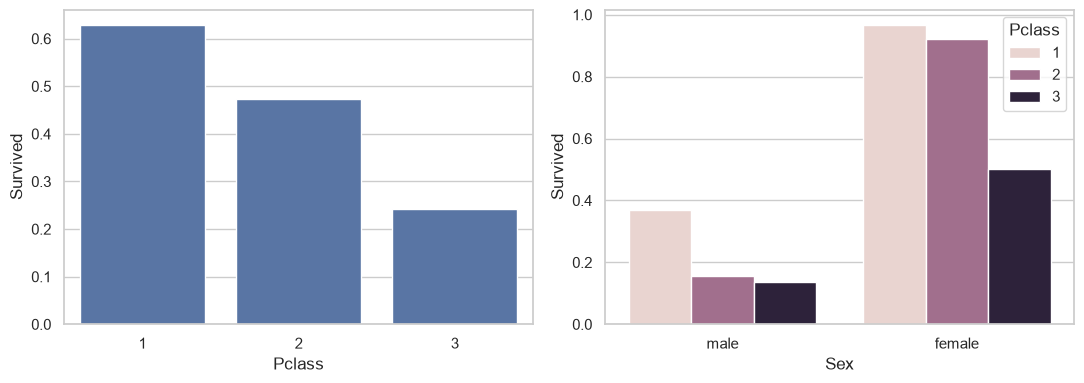

Survie par classe/sexe :


count      mean
Pclass Sex                    
1      female     94  0.968085
       male      122  0.368852
2      female     76  0.921053
       male      108  0.157407
3      female    144  0.500000
       male      347  0.135447

,count,mean
Age,,
"(-0.001, 12.0]",69,0.579710
"(12.0, 18.0]",70,0.428571
"(18.0, 35.0]",358,0.382682
"(35.0, 60.0]",195,0.400000
"(60.0, 100.0]",22,0.227273


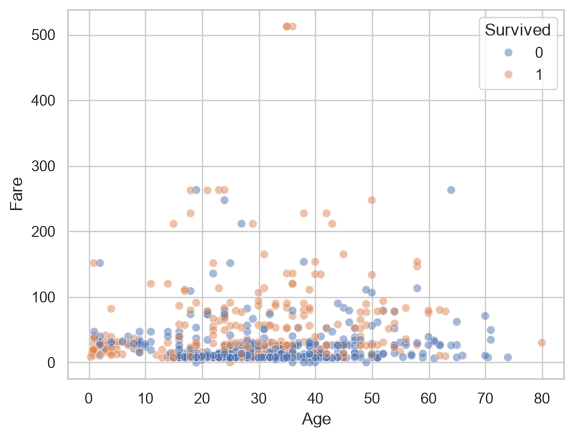

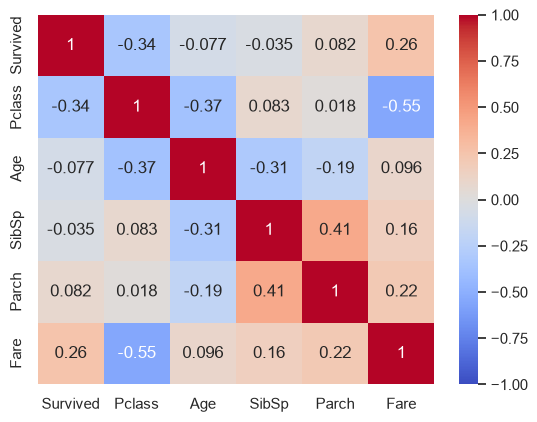

In [3]:
titanic = load('train')
display(titanic.head());titanic.info();display(titanic.describe(include='all'))
display(titanic.isna().sum().to_frame('manquants avant'))
titanic_clean = titanic.copy()
titanic_clean['AgeMissing'] = titanic_clean['Age'].isna()
age_group_median = titanic_clean.groupby(['Pclass','Sex'])['Age'].transform('median')
titanic_clean['Age'] = titanic_clean['Age'].fillna(age_group_median).fillna(titanic['Age'].median())
titanic_clean['Embarked'] = titanic_clean['Embarked'].fillna(titanic['Embarked'].mode()[0])
titanic_clean['CabinKnown'] = titanic_clean['Cabin'].notna()
titanic_clean['Cabin'] = titanic_clean['Cabin'].fillna('Unknown')
titanic_clean['SexCode'] = titanic_clean['Sex'].map({'female':0,'male':1})
encoded = pd.get_dummies(titanic_clean,columns=['Embarked'],dtype=int)
assert titanic_clean[['Age','Embarked','Cabin']].notna().all().all()
titanic_clean.to_csv(RESULTS/'titanic_clean.csv',index=False)
display(titanic_clean.isna().sum().to_frame('manquants après'))
titanic[['Age','Fare']].hist(figsize=(10,4),bins=25);plt.show()
fig,axs=plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=titanic,x='Pclass',y='Survived',errorbar=None,ax=axs[0])
sns.barplot(data=titanic,x='Sex',y='Survived',hue='Pclass',errorbar=None,ax=axs[1]);plt.tight_layout();plt.show()
print('Survie par classe/sexe :');display(titanic.groupby(['Pclass','Sex'])['Survived'].agg(['count','mean']))
age_bands = pd.cut(titanic['Age'],[0,12,18,35,60,100],include_lowest=True)
display(titanic.groupby(age_bands,observed=True)['Survived'].agg(['count','mean']))
sns.scatterplot(data=titanic,x='Age',y='Fare',hue='Survived',alpha=.5);plt.show()
sns.heatmap(titanic[['Survived','Pclass','Age','SibSp','Parch','Fare']].corr(),annot=True,cmap='coolwarm',vmin=-1,vmax=1);plt.show()

Les taux de survie sont plus élevés en première classe et chez les femmes ; le tableau classe/sexe montre que ces facteurs se combinent. Les classes d'âge incluent seulement les âges observés afin de ne pas transformer une imputation en constat empirique. Les graphiques descriptifs utilisent les données originales ; la copie nettoyée est conservée pour les étapes ultérieures. `CabinKnown` et `AgeMissing` préservent l'information de manque. L'imputation par médiane réduit la variance et n'est pas une estimation certaine de l'âge individuel. Pour une prédiction, il faudrait ajuster l'imputation sur le seul ensemble d'entraînement.

## Exercice 3 — Iris : analyses univariée, bivariée et multivariée

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Doublons sans identifiant : 3


SepalLengthCm                     SepalWidthCm                 \
                         mean       std  min  max         mean       std  min   
Species                                                                         
Iris-setosa             5.006  0.352490  4.3  5.8        3.418  0.381024  2.3   
Iris-versicolor         5.936  0.516171  4.9  7.0        2.770  0.313798  2.0   
Iris-virginica          6.588  0.635880  4.9  7.9        2.974  0.322497  2.2   

                     PetalLengthCm                     PetalWidthCm            \
                 max          mean       std  min  max         mean       std   
Species                                                                         
Iris-setosa      4.4         1.464  0.173511  1.0  1.9        0.244  0.107210   
Iris-versicolor  3.4         4.260  0.469911  3.0  5.1        1.326  0.197753   
Iris-virginica   3.8         5.552  0.551895  4.5  6.9        2.026  0.274650   

                           
                 min  max  
Species                    
Iris-setosa      0.1  0.6  
Iris-versicolor  1.0  1.8  
Iris-virginica   1.4  2.5

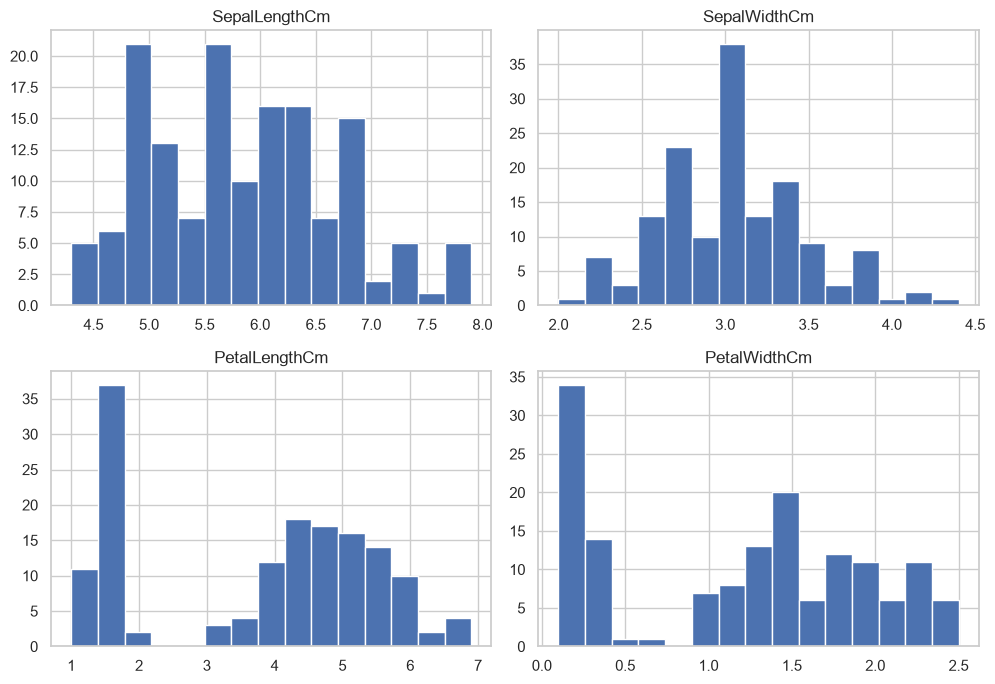

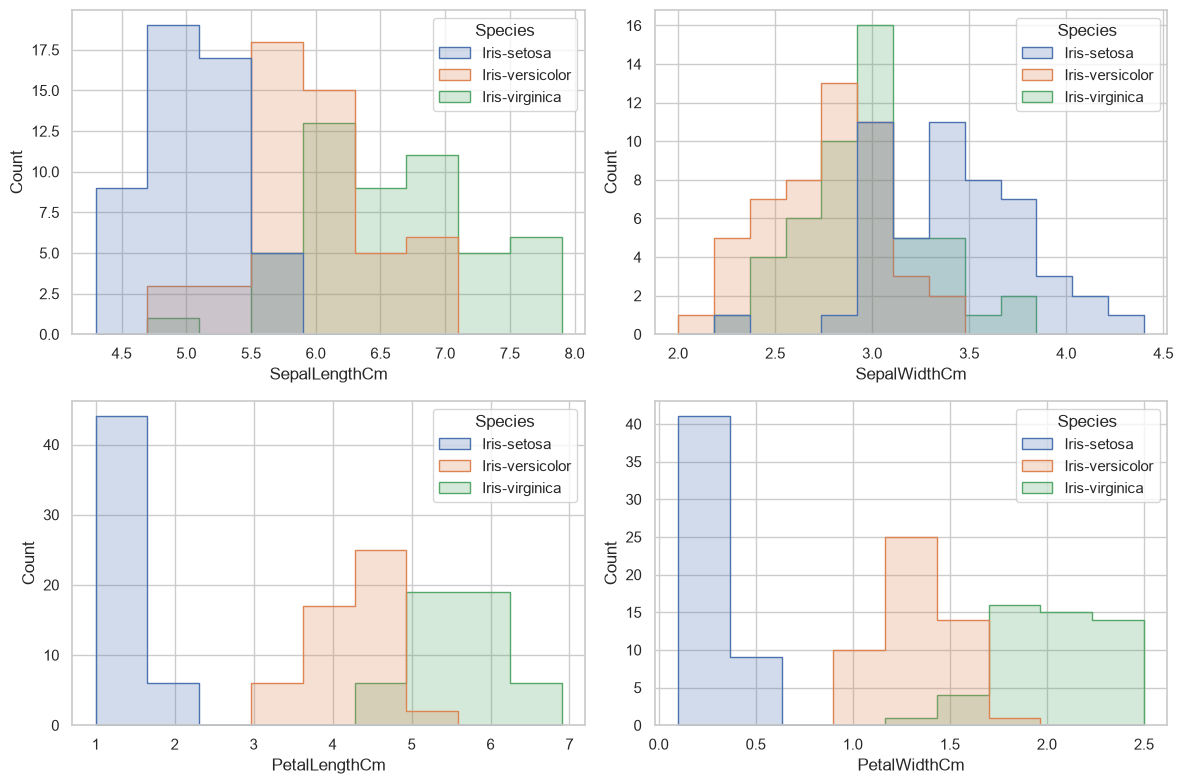

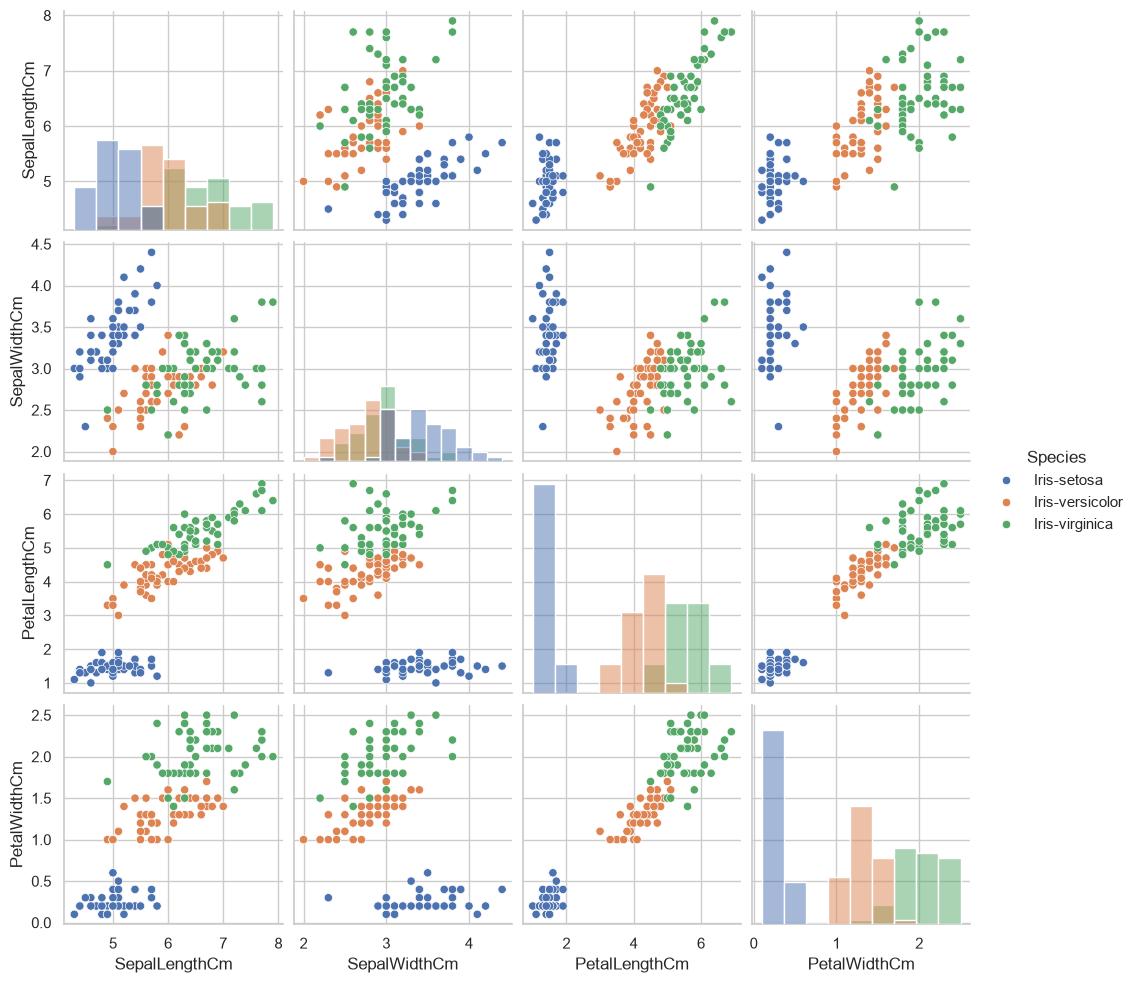

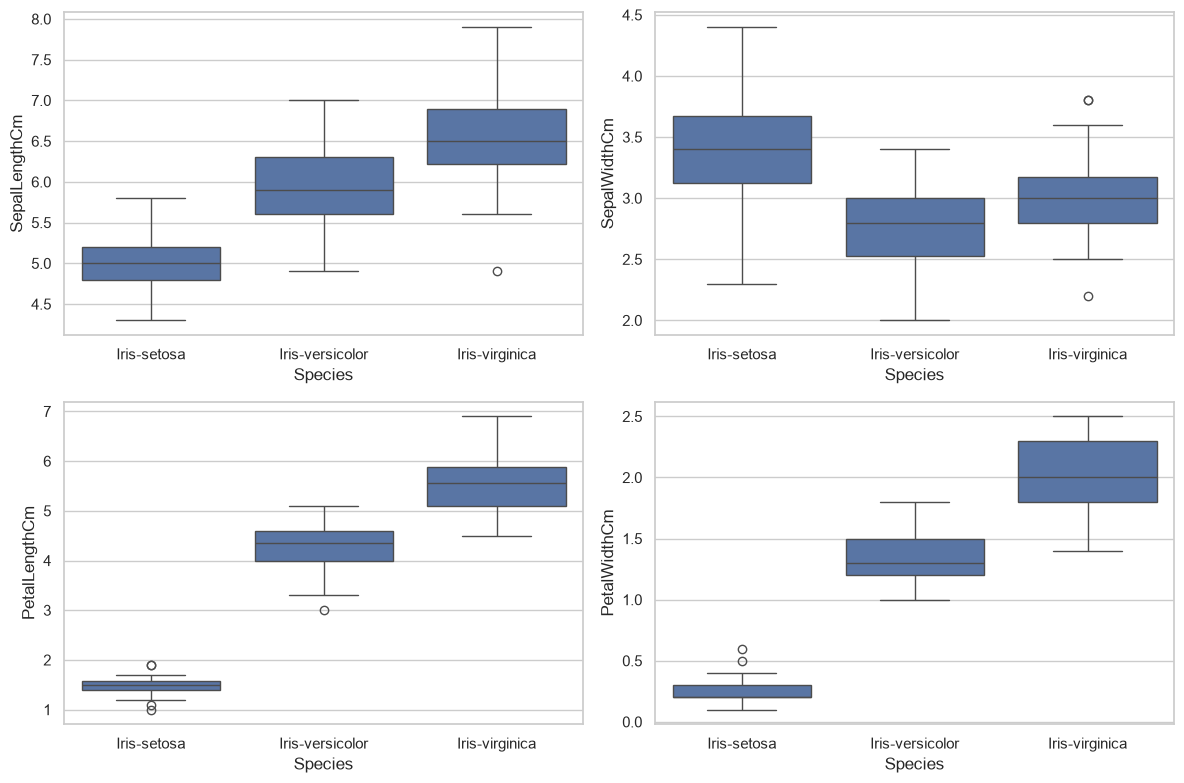

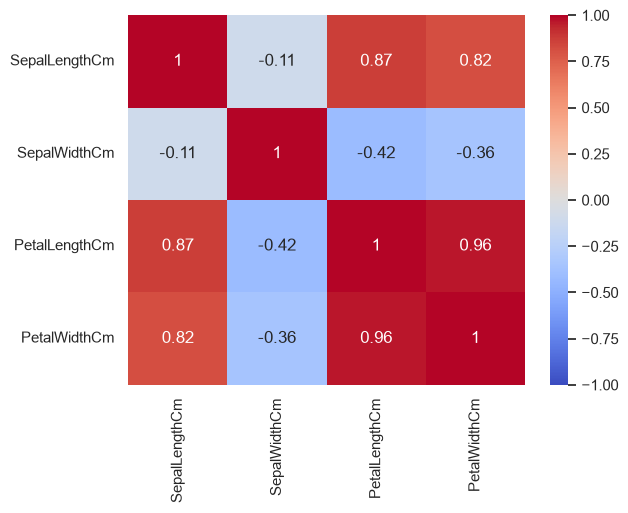

In [4]:
iris = load('Iris Dataset')
cols = list(iris.filter(regex='Cm$').columns)
display(iris.head());iris.info();display(iris.describe());display(iris.isna().sum())
display(iris['Species'].value_counts());print('Doublons sans identifiant :',iris.drop(columns='Id').duplicated().sum())
display(iris.groupby('Species')[cols].agg(['mean','std','min','max']))
iris[cols].hist(figsize=(10,7),bins=15);plt.tight_layout();plt.show()
fig,axs = plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axs.flat,cols):
    sns.histplot(data=iris,x=col,hue='Species',element='step',ax=ax)
plt.tight_layout();plt.show()
sns.pairplot(iris[cols+['Species']],hue='Species',diag_kind='hist');plt.show()
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axs.flat,cols):
    sns.boxplot(data=iris,x='Species',y=col,ax=ax)
plt.tight_layout();plt.show()
sns.heatmap(iris[cols].corr(),annot=True,cmap='coolwarm',vmin=-1,vmax=1);plt.show()

Setosa se distingue par ses petites pétales ; Virginica présente en moyenne les pétales les plus grandes ; Versicolor occupe une zone intermédiaire et se recouvre partiellement avec Virginica. Les sépales seuls séparent moins nettement les espèces. Le pairplot montre les six paires de mesures et la structure multivariée. Une corrélation globale peut être dominée par les différences entre espèces. Un doublon de mesures sans Id n'est pas automatiquement un doublon de fleur ; aucune suppression arbitraire n'est effectuée.

## Exercice 4 — Ventes de produits et tickets de support

Dates calendaires invalides : 26


,original_date
109,31-9-2010
170,31-11-2010
473,31-9-2011
534,31-11-2011
836,31-9-2012
897,31-11-2012
1200,31-9-2013
1261,31-11-2013
1564,31-9-2014
1625,31-11-2014


,Unnamed: 0,Date,Q-P1,Q-P2,Q-P3,Q-P4,S-P1,S-P2,S-P3,S-P4
0,0,2010-06-13,5422,3725,576,907,17187.74,23616.50,3121.92,6466.91
1,1,2010-06-14,7047,779,3578,1574,22338.99,4938.86,19392.76,11222.62
2,2,2010-06-15,1572,2082,595,1145,4983.24,13199.88,3224.90,8163.85
3,3,2010-06-16,5657,2399,3140,1672,17932.69,15209.66,17018.80,11921.36
4,4,2010-06-17,3668,3207,2184,708,11627.56,20332.38,11837.28,5048.04


,Unnamed: 0,Date,Q-P1,Q-P2,Q-P3,Q-P4,S-P1,S-P2,S-P3,S-P4
count,4600.000000,4574,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,2299.500000,2016-10-08 02:26:42.448622,4121.849130,2130.281522,3145.740000,1123.500000,13066.261743,13505.984848,17049.910800,8010.555000
min,0.000000,2010-06-13 00:00:00,254.000000,251.000000,250.000000,250.000000,805.180000,1591.340000,1355.000000,1782.500000
25%,1149.750000,2013-08-10 06:00:00,2150.500000,1167.750000,1695.750000,696.000000,6817.085000,7403.535000,9190.965000,4962.480000
50%,2299.500000,2016-10-08 12:00:00,4137.000000,2134.000000,3202.500000,1136.500000,13114.290000,13529.560000,17357.550000,8103.245000
75%,3449.250000,2019-12-05 18:00:00,6072.000000,3070.250000,4569.000000,1544.000000,19248.240000,19465.385000,24763.980000,11008.720000
max,4599.000000,2023-02-03 00:00:00,7998.000000,3998.000000,6000.000000,2000.000000,25353.660000,25347.320000,32520.000000,14260.000000
std,1328.049949,NaN,2244.271323,1089.783705,1671.832231,497.385676,7114.340094,6909.228687,9061.330694,3546.359869


,quantité_totale,ventes_totales
P1,18960506,60104804.02
P2,9799295,62127530.30
P3,14470404,78429589.68
P4,5168100,36848553.00


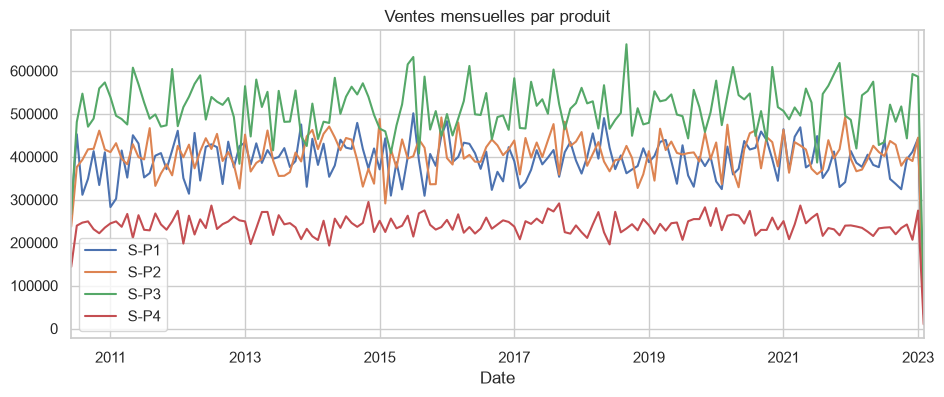

,Ticket ID,Ticket Type,Ticket Subject,Ticket Status,Ticket Priority
0,1,Technical issue,Product setup,Pending Customer Response,Critical
1,2,Technical issue,Peripheral compatibility,Pending Customer Response,Critical
2,3,Technical issue,Network problem,Closed,Low
3,4,Billing inquiry,Account access,Closed,Low
4,5,Billing inquiry,Data loss,Closed,Low


Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Ticket Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64

sentiment_estimé
neutre     4266
positif    2949
négatif    1254
Name: count, dtype: int64

,mot,occurrences
0,product,16998
1,purchased,14454
2,issue,11532
3,please,8815
4,having,6430
5,assist,6258
6,can,2449
7,problem,2285
8,any,2048
9,there,1749


Textes contenant un placeholder : 8469
Satisfaction moyenne renseignée : 2.991332611050921
Part de satisfaction absente : 0.6730428622033298


In [5]:
product_sales = load('Product Sales Dataset')
original_dates = product_sales['Date'].copy()
product_sales['Date'] = pd.to_datetime(original_dates,format='%d-%m-%Y',errors='coerce')
invalid_dates = product_sales.loc[product_sales['Date'].isna()].assign(original_date=original_dates)
print('Dates calendaires invalides :',len(invalid_dates))
display(invalid_dates[['original_date']].head(10))
invalid_dates.to_csv(RESULTS/'product_sales_invalid_dates.csv',index=False)
display(product_sales.head());display(product_sales.describe())
quantities = product_sales.filter(regex=r'^Q-P')
amounts = product_sales.filter(regex=r'^S-P')
display(pd.DataFrame({'quantité_totale':quantities.sum().to_numpy(),'ventes_totales':amounts.sum().to_numpy()},index=['P1','P2','P3','P4']))
product_sales.dropna(subset=['Date']).set_index('Date')[list(amounts)].resample('ME').sum().plot(figsize=(11,4),title='Ventes mensuelles par produit');plt.show()
tickets = load('Customer Support Ticket Dataset')
display(tickets[['Ticket ID','Ticket Type','Ticket Subject','Ticket Status','Ticket Priority']].head())
display(tickets['Ticket Type'].value_counts());display(tickets['Ticket Status'].value_counts())
support_text, support_words = text_analysis(tickets['Ticket Description'])
display(support_text['sentiment_estimé'].value_counts())
display(pd.DataFrame(support_words.most_common(15),columns=['mot','occurrences']))
print('Textes contenant un placeholder :',tickets['Ticket Description'].fillna('').str.contains('{product_purchased}',regex=False).sum())
print('Satisfaction moyenne renseignée :',tickets['Customer Satisfaction Rating'].mean())
print('Part de satisfaction absente :',tickets['Customer Satisfaction Rating'].isna().mean())

Les colonnes Q-P représentent les quantités et S-P les montants selon les noms fournis ; l'unité monétaire n'est pas documentée ici. `Unnamed: 0` est un index exporté. Les tickets sont un dataset mixte : catégories structurées et descriptions libres. Le comptage de types de demandes est immédiat ; l'extraction de motifs à partir du texte nécessite normalisation et interprétation. Les placeholders `{product_purchased}` témoignent de textes templatisés et limitent les conclusions. Les mots de facturation, assistance ou produit peuvent refléter un modèle de génération, pas un problème réellement fréquent. TextBlob ne remplace pas l'annotation humaine. Les taux de satisfaction ne portent que sur les réponses renseignées, qui peuvent être biaisées. Aucun lien n'établit que les deux jeux concernent les mêmes produits ou clients.

Les dates impossibles du fichier (par exemple un 31 septembre) sont signalées et exportées. Elles restent dans les totaux de quantités et montants, mais sont exclues du graphique temporel, sans inventer une date de remplacement.

## Exercice 5 — Tweets : extraction vers un format structuré

In [6]:
import re, json
tweets = load('Twitter Tweets Sentiment Dataset')
print('Tweets sans texte :',tweets['text'].isna().sum())
structured = tweets[['textID','sentiment']].copy()
text = tweets['text'].fillna('')
structured['hashtags'] = text.map(lambda s: re.findall(r'(?<!\w)#[\w]+',s))
structured['mentions'] = text.map(lambda s: re.findall(r'(?<!\w)@[\w]+',s))
structured['has_text'] = tweets['text'].notna()
structured['character_count'] = text.str.len()
structured['hashtag_count'] = structured['hashtags'].map(len)
structured['mention_count'] = structured['mentions'].map(len)
assert len(structured)==len(tweets)
assert structured.loc[~structured['has_text'],'character_count'].eq(0).all()
display(structured.head())
display(structured.groupby('sentiment').agg(tweets=('textID','size'),longueur_moyenne=('character_count','mean'),part_avec_hashtag=('hashtag_count',lambda x:x.gt(0).mean()),part_avec_mention=('mention_count',lambda x:x.gt(0).mean())))
print('Hashtags fréquents :',structured['hashtags'].explode().dropna().str.lower().value_counts().head(10))
print('Mentions fréquentes :',structured['mentions'].explode().dropna().str.lower().value_counts().head(10))
structured.to_json(RESULTS/'tweets_structured.json',orient='records',force_ascii=False,indent=2)
csv_version = structured.copy()
for col in ['hashtags','mentions']:csv_version[col]=csv_version[col].map(json.dumps)
csv_version.to_csv(RESULTS/'tweets_structured.csv',index=False)

Tweets sans texte : 1


,textID,sentiment,hashtags,mentions,has_text,character_count,hashtag_count,mention_count
0,cb774db0d1,neutral,[],[],True,36,0,0
1,549e992a42,negative,[],[],True,46,0,0
2,088c60f138,negative,[],[],True,25,0,0
3,9642c003ef,negative,[],[],True,31,0,0
4,358bd9e861,negative,[],[],True,75,0,0


,tweets,longueur_moyenne,part_avec_hashtag,part_avec_mention
sentiment,,,,
negative,7781,70.488112,0.019149,0.002699
neutral,11118,65.200935,0.019248,0.002878
positive,8582,70.419133,0.018411,0.002447


Hashtags fréquents : hashtags
#fb              31
#followfriday    23
#bgt             20
#ff              11
#starwarsday      9
#fail             7
#1                7
#2                6
#twpp             6
#juddday          6
Name: count, dtype: int64
Mentions fréquentes : mentions
@_supernatural_     4
@_erica             3
@_elj               2
@_writersblock_     2
@_hayles            2
@_bella_cullen13    2
@_ra_ra_            1
@_agressiva23       1
@_anshul            1
@_twee              1
Name: count, dtype: int64


Le sentiment est conservé depuis la colonne d'origine, sans ré-étiquetage. Les nouvelles colonnes permettent de comparer présence de hashtags, mentions et longueur entre sentiments, ce qui nécessitait auparavant une lecture manuelle. Les listes vides ne signifient pas une absence d'opinion. Une chaîne absente reste distinguée d'un vrai texte vide par `has_text`. La regex ne capture pas tous les cas propres à chaque plateforme ; aucune causalité entre mention et sentiment n'est déduite. Les textes originaux restent accessibles via `textID`.